In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
df = pd.read_csv("/kaggle/input/competitions/aptos2019-blindness-detection/train.csv")
df.head()

,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [3]:
PATH = "/kaggle/input/competitions/aptos2019-blindness-detection/train_images"
x, y = [], []

for index, row in df.iterrows():
    img_name = str(row['id_code']) + '.png' 
    class_num = row['diagnosis']
    path = os.path.join(PATH, img_name)

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (128, 128))
    
    x.append(img)
    y.append(class_num)

In [4]:
x = np.array(x).reshape(-1, 128, 128, 1)
y = np.array(y)

x = x / 255.0

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)
print(len(x_train), len(x_test))

2929 733


**Model A: 3×3 MaxPool**

In [7]:
model_A = keras.Sequential([
    keras.Input(shape=(128, 128, 1)),
    
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(3),

    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(3),

    layers.Flatten(),
    
    layers.Dense(32, activation='relu'),
    layers.Dense(5, activation='softmax') 
])

model_A.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 42, 42, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 42, 42, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │       401,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,421 (1.60 MB)

 Trainable params: 420,421 (1.60 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model_A.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_A = model_A.fit(x_train, y_train, batch_size=128, epochs=15)

Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 12s 222ms/step - accuracy: 0.5903 - loss: 1.1006
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.6849 - loss: 0.8639
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.6992 - loss: 0.8097
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7112 - loss: 0.7739
Epoch 5/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7177 - loss: 0.7630
Epoch 6/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7194 - loss: 0.7534
Epoch 7/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7245 - loss: 0.7404
Epoch 8/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7323 - loss: 0.7295
Epoch 9/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7364 - loss: 0.7109
Epoch 10/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7433 - loss: 0.6964
Epoch 11/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7474 - loss: 0.6834
Epoch 12/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accurac

In [10]:
loss_a, acc_a = model_A.evaluate(x_test, y_test)
print(f'Test Accuracy of Model_A: {acc_a:.2%}')
print(f'Test Loss of Model_A: {loss_a:.4f}')

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.7299 - loss: 0.7506
Test Accuracy of Model_A: 72.99%
Test Loss of Model_A: 0.7506


**Model B: 5×5 MaxPool**

In [11]:
model_B = keras.Sequential([
    keras.Input(shape=(128, 128, 1)),
    
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(5),

    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(5),

    layers.Flatten(),
    
    layers.Dense(32, activation='relu'),
    layers.Dense(5, activation='softmax') 
])

model_B.summary()
model_B.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_B = model_B.fit(x_train, y_train, batch_size=128, epochs=15)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 25, 25, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │        51,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70,213 (274.27 KB)

 Trainable params: 70,213 (274.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 123ms/step - accuracy: 0.4964 - loss: 1.3045
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6357 - loss: 1.0171
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6808 - loss: 0.8749
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6886 - loss: 0.8374
Epoch 5/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7013 - loss: 0.8075
Epoch 6/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7054 - loss: 0.7854
Epoch 7/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7166 - loss: 0.7747
Epoch 8/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7197 - loss: 0.7644
Epoch 9/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7310 - loss: 0.7509
Epoch 10/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7320 - loss: 0.7421
Epoch 11/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7327 - loss: 0.7385
Epoch 12/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy

In [12]:
loss_b, acc_b = model_B.evaluate(x_test, y_test)
print(f'Test Accuracy of Model_B: {acc_b:.2%}')
print(f'Test Loss of Model_B: {loss_b:.4f}')

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.7271 - loss: 0.7507
Test Accuracy of Model_B: 72.71%
Test Loss of Model_B: 0.7507


**Model C: 3×3 Avgpool**

In [13]:
model_C = keras.Sequential([
    keras.Input(shape=(128, 128, 1)),
    
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.AveragePooling2D(3),

    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.AveragePooling2D(3),

    layers.Flatten(),
    
    layers.Dense(32, activation='relu'),
    layers.Dense(5, activation='softmax') 
])

model_C.summary()
model_C.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_C = model_C.fit(x_train, y_train, batch_size=128, epochs=15)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 42, 42, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 42, 42, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │       401,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,421 (1.60 MB)

 Trainable params: 420,421 (1.60 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - accuracy: 0.5476 - loss: 1.1873
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.6617 - loss: 0.9486
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6743 - loss: 0.8821
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6927 - loss: 0.8436
Epoch 5/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6893 - loss: 0.8226
Epoch 6/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6958 - loss: 0.8043
Epoch 7/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7071 - loss: 0.7848
Epoch 8/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7129 - loss: 0.7698
Epoch 9/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7139 - loss: 0.7706
Epoch 10/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7159 - loss: 0.7593
Epoch 11/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7156 - loss: 0.7490
Epoch 12/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy

In [14]:
loss_c, acc_c = model_C.evaluate(x_test, y_test)
print(f'Test Accuracy of Model_C: {acc_c:.2%}')
print(f'Test Loss of Model_C: {loss_c:.4f}')

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.7190 - loss: 0.7861
Test Accuracy of Model_C: 71.90%
Test Loss of Model_C: 0.7861


**Compare 3 models**

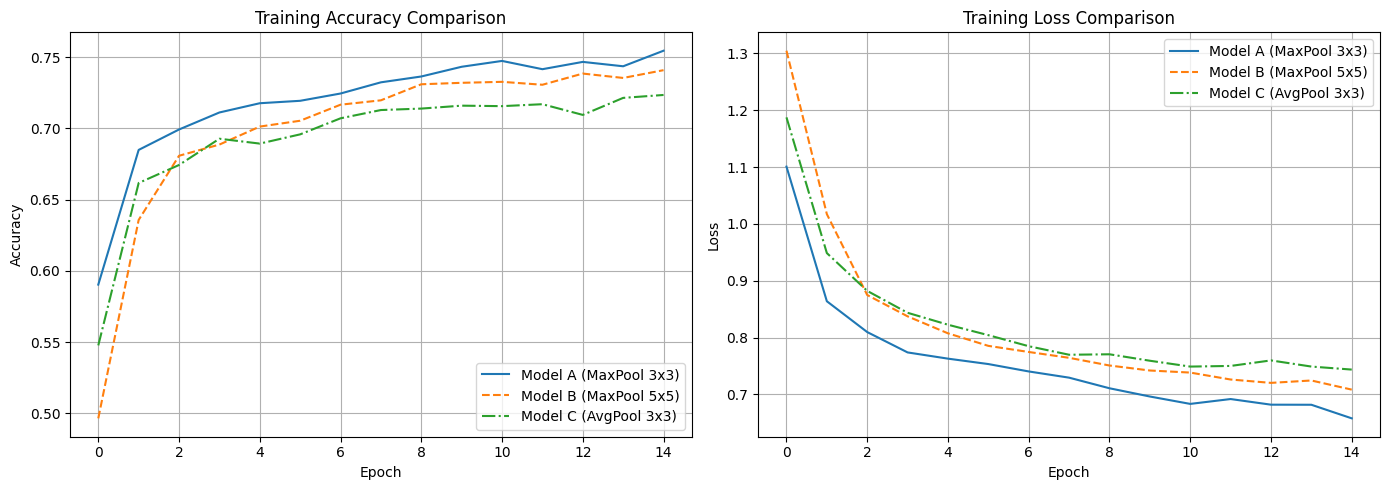

In [15]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_A.history['accuracy'], label='Model A (MaxPool 3x3)', linestyle='-')
plt.plot(history_B.history['accuracy'], label='Model B (MaxPool 5x5)', linestyle='--')
plt.plot(history_C.history['accuracy'], label='Model C (AvgPool 3x3)', linestyle='-.')
plt.title('Training Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_A.history['loss'], label='Model A (MaxPool 3x3)', linestyle='-')
plt.plot(history_B.history['loss'], label='Model B (MaxPool 5x5)', linestyle='--')
plt.plot(history_C.history['loss'], label='Model C (AvgPool 3x3)', linestyle='-.')
plt.title('Training Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()